# RoadScan — YOLO26n Fine-Tuning

Continue from the baseline `best.pt` (validation mAP50 = 50.6%) and compare before vs after fine-tuning.


In [6]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [3]:
!pip -q install -U ultralytics


In [3]:
from pathlib import Path
import shutil, random
import numpy as np
import pandas as pd
import torch
from ultralytics import YOLO

SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print("CUDA:", torch.cuda.is_available())
if torch.cuda.is_available(): print("GPU:", torch.cuda.get_device_name(0))


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
CUDA: True
GPU: Tesla T4


In [4]:
DATA_SOURCE = Path("/content/drive/MyDrive/RoadScan_RDD_SaudiRD2_Validated.zip")
BASELINE_BEST = Path("/content/drive/MyDrive/RoadScan_P/RoadScan_YOLO26n_Reproduction/yolo26n_640_20epochs/weights/best.pt")
OUTPUT_BASE = Path("/content/drive/MyDrive/RoadScan_P/RoadScan_YOLO26n_FineTuning")

assert DATA_SOURCE.is_file(), f"Dataset not found: {DATA_SOURCE}"
assert BASELINE_BEST.is_file(), f"best.pt not found: {BASELINE_BEST}"
OUTPUT_BASE.mkdir(parents=True, exist_ok=True)
print("Dataset:", DATA_SOURCE)
print("Starting weights:", BASELINE_BEST)


Dataset: /content/drive/MyDrive/RoadScan_RDD_SaudiRD2_Validated.zip
Starting weights: /content/drive/MyDrive/RoadScan_P/RoadScan_YOLO26n_Reproduction/yolo26n_640_20epochs/weights/best.pt


In [5]:
EXTRACT_ROOT=Path("/content/roadscan_finetune_data")
if EXTRACT_ROOT.exists(): shutil.rmtree(EXTRACT_ROOT)
EXTRACT_ROOT.mkdir(parents=True)
shutil.unpack_archive(str(DATA_SOURCE), str(EXTRACT_ROOT))
yamls=list(EXTRACT_ROOT.rglob("data.yaml"))
assert yamls, "data.yaml not found"
RDD_YAML=yamls[0]
print("data.yaml:", RDD_YAML)
print(RDD_YAML.read_text())


data.yaml: /content/roadscan_finetune_data/RoadScan_RDD_SaudiRD2_Validated/data.yaml
train: images/train
val: images/val
test: images/test
names:
  0: longitudinal_crack
  1: transverse_crack
  2: alligator_crack
  3: pothole



In [6]:
# Fine-tuning: same model/data/resolution, lower learning rate.
IMGSZ=640
EPOCHS=20
PATIENCE=10
BATCH=8
WORKERS=2

FINETUNE_ARGS=dict(
    epochs=EPOCHS, patience=PATIENCE, batch=BATCH, nbs=64,
    optimizer="AdamW", lr0=0.0002, lrf=0.01, weight_decay=0.0005,
    cos_lr=True, warmup_epochs=1.0,
    fliplr=0.5, flipud=0.0, mosaic=0.3, mixup=0.0,
    hsv_h=0.015, hsv_s=0.3, hsv_v=0.25,
    degrees=0.0, translate=0.05, scale=0.25,
    shear=0.0, perspective=0.0,
    close_mosaic=5, amp=True, seed=SEED, deterministic=True,
    cache=False, save=True, save_period=1, plots=True
)
print("Fine-tuning settings ready.")


Fine-tuning settings ready.


In [7]:
RUN_NAME="yolo26n_finetune_20epochs"
model=YOLO(str(BASELINE_BEST))
model.train(
    data=str(RDD_YAML), imgsz=IMGSZ, device=0, workers=WORKERS,
    project=str(OUTPUT_BASE), name=RUN_NAME, exist_ok=True,
    **FINETUNE_ARGS
)

RUN_DIR=OUTPUT_BASE/RUN_NAME
FINETUNED_BEST=RUN_DIR/"weights"/"best.pt"
assert FINETUNED_BEST.is_file()
print("Fine-tuned best.pt:", FINETUNED_BEST)


Ultralytics 8.4.187 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/roadscan_finetune_data/RoadScan_RDD_SaudiRD2_Validated/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.3, hsv_v=0.25, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.0002, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/RoadScan_P/RoadScan_YOLO26n_Reproduction/yolo26n_640_20

In [8]:
ft_model=YOLO(str(FINETUNED_BEST))
m=ft_model.val(
    data=str(RDD_YAML), split="val", imgsz=640, batch=4,
    device=0, workers=WORKERS, conf=0.001, iou=0.6,
    max_det=300, plots=True
)
after={
    "mAP50":float(m.box.map50),
    "mAP50-95":float(m.box.map),
    "Precision":float(m.box.mp),
    "Recall":float(m.box.mr)
}
print("\nAFTER FINE-TUNING")
for k,v in after.items(): print(f"{k}: {v*100:.2f}%")


Ultralytics 8.4.187 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3631.8±552.9 MB/s, size: 147.3 KB)
val: Scanning /content/roadscan_finetune_data/RoadScan_RDD_SaudiRD2_Validated/labels/val.cache... 800 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 800/800 239.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 200/200 21.7it/s 9.2s
                   all        800       1440      0.599      0.505      0.533      0.245
    longitudinal_crack        240        360      0.538      0.383      0.398      0.182
      transverse_crack        240        360      0.651      0.531      0.592      0.281
       alligator_crack        240        360       0.64      0.633      0.632      0.306
               pothole        240        360      0.569      0.473       0.51      0

In [9]:
before={"mAP50":0.506,"mAP50-95":0.241,"Precision":0.604,"Recall":0.461}
comparison=pd.DataFrame([
    {"Method":"Before Fine-tuning",**before},
    {"Method":"After Fine-tuning",**after}
])
comparison["F1"]=2*comparison["Precision"]*comparison["Recall"]/(comparison["Precision"]+comparison["Recall"])
for col in ["mAP50","mAP50-95","Precision","Recall","F1"]:
    comparison[col]*=100
display(comparison.round(2))
change=comparison.loc[1,"mAP50"]-comparison.loc[0,"mAP50"]
print(f"mAP50 change: {change:+.2f} percentage points")
comparison.to_csv(OUTPUT_BASE/"before_vs_after_finetuning.csv",index=False)


,Method,mAP50,mAP50-95,Precision,Recall,F1
0,Before Fine-tuning,50.60,24.10,60.40,46.1,52.29
1,After Fine-tuning,53.31,24.46,59.94,50.5,54.82


mAP50 change: +2.71 percentage points


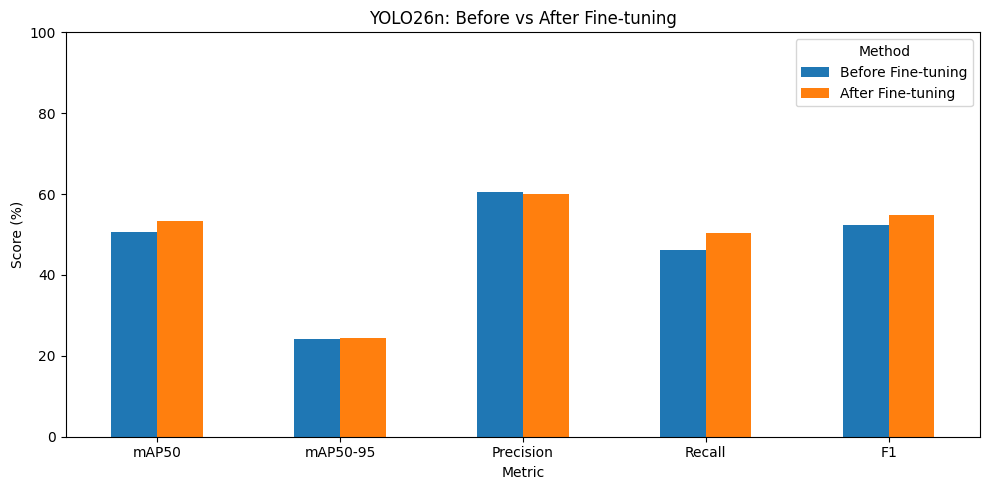

Chart saved: /content/drive/MyDrive/RoadScan_P/RoadScan_YOLO26n_FineTuning/before_vs_after_finetuning.png


In [10]:
import matplotlib.pyplot as plt
plot_df=comparison.set_index("Method")[["mAP50","mAP50-95","Precision","Recall","F1"]]
ax=plot_df.T.plot(kind="bar",figsize=(10,5))
ax.set_title("YOLO26n: Before vs After Fine-tuning")
ax.set_ylabel("Score (%)"); ax.set_xlabel("Metric"); ax.set_ylim(0,100)
ax.legend(title="Method"); plt.xticks(rotation=0); plt.tight_layout()
chart=OUTPUT_BASE/"before_vs_after_finetuning.png"
plt.savefig(chart,dpi=180,bbox_inches="tight"); plt.show()
print("Chart saved:",chart)


In [11]:
FINAL_COPY=OUTPUT_BASE/"best_yolo26n_after_finetuning.pt"
shutil.copy2(FINETUNED_BEST,FINAL_COPY)
print("Final fine-tuned weight:",FINAL_COPY)


Final fine-tuned weight: /content/drive/MyDrive/RoadScan_P/RoadScan_YOLO26n_FineTuning/best_yolo26n_after_finetuning.pt


In [7]:
from ultralytics import YOLO
from pathlib import Path

# Fine-tuned model saved in Google Drive
FINAL_COPY = Path(
    "/content/drive/MyDrive/RoadScan_P/RoadScan_YOLO26n_FineTuning/best_yolo26n_after_finetuning.pt"
)

print("Model exists:", FINAL_COPY.exists())

test_model = YOLO(str(FINAL_COPY))

Model exists: True


In [8]:
import zipfile
from pathlib import Path

# Dataset
DATA_ZIP = Path("/content/drive/MyDrive/RoadScan_RDD_SaudiRD2_Validated.zip")
TEST_DIR = Path("/content/roadscan_test_data")

print("Dataset exists:", DATA_ZIP.exists())

# Extract dataset
if not TEST_DIR.exists():
    with zipfile.ZipFile(DATA_ZIP, "r") as zip_ref:
        zip_ref.extractall(TEST_DIR)

# Find data.yaml
yaml_files = list(TEST_DIR.rglob("data.yaml"))

print("Found YAML files:", yaml_files)

Dataset exists: True
Found YAML files: [PosixPath('/content/roadscan_test_data/RoadScan_RDD_SaudiRD2_Validated/data.yaml')]


In [9]:
from pathlib import Path

TEST_YAML = Path(
    "/content/roadscan_test_data/RoadScan_RDD_SaudiRD2_Validated/data.yaml"
)

test_results = test_model.val(
    data=str(TEST_YAML),
    split="test",
    imgsz=640,
    batch=8,
    plots=True
)

p = test_results.box.mp
r = test_results.box.mr
f1 = 2 * p * r / (p + r) if (p + r) > 0 else 0

print("\n===== FINE-TUNING — TEST RESULTS =====")
print(f"mAP50:     {test_results.box.map50 * 100:.2f}%")
print(f"mAP50-95:  {test_results.box.map * 100:.2f}%")
print(f"Precision: {p * 100:.2f}%")
print(f"Recall:    {r * 100:.2f}%")
print(f"F1:        {f1 * 100:.2f}%")

Ultralytics 8.4.187 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 849.8±973.7 MB/s, size: 132.6 KB)
val: Scanning /content/roadscan_test_data/RoadScan_RDD_SaudiRD2_Validated/labels/test... 800 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 800/800 835.7it/s 1.0s
val: New cache created: /content/roadscan_test_data/RoadScan_RDD_SaudiRD2_Validated/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 100/100 7.3it/s 13.8s
                   all        800       1440      0.587      0.493        0.5      0.242
    longitudinal_crack        240        360      0.612      0.421      0.452      0.216
      transverse_crack        240        360      0.579      0.528       0.51      0.253
       alligator_crack        240        360      0.606      0.581      0.576     

In [10]:
from ultralytics import YOLO
from pathlib import Path

# Original baseline model BEFORE fine-tuning
BASELINE_BEST = Path(
    "/content/drive/MyDrive/RoadScan_P/RoadScan_YOLO26n_Reproduction/"
    "yolo26n_640_20epochs/weights/best.pt"
)

print("Baseline exists:", BASELINE_BEST.exists())

baseline_model = YOLO(str(BASELINE_BEST))

baseline_test = baseline_model.val(
    data=str(TEST_YAML),
    split="test",
    imgsz=640,
    batch=8,
    plots=False
)

bp = baseline_test.box.mp
br = baseline_test.box.mr
bf1 = 2 * bp * br / (bp + br) if (bp + br) > 0 else 0

print("\n===== BASELINE — TEST RESULTS =====")
print(f"mAP50:     {baseline_test.box.map50 * 100:.2f}%")
print(f"mAP50-95:  {baseline_test.box.map * 100:.2f}%")
print(f"Precision: {bp * 100:.2f}%")
print(f"Recall:    {br * 100:.2f}%")
print(f"F1:        {bf1 * 100:.2f}%")

Baseline exists: True
Ultralytics 8.4.187 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2934.4±906.5 MB/s, size: 173.5 KB)
val: Scanning /content/roadscan_test_data/RoadScan_RDD_SaudiRD2_Validated/labels/test.cache... 800 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 800/800 197.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 100/100 11.1it/s 9.0s
                   all        800       1440      0.542       0.49      0.479      0.227
    longitudinal_crack        240        360      0.564      0.414      0.428        0.2
      transverse_crack        240        360      0.563       0.55      0.505      0.247
       alligator_crack        240        360      0.561      0.558      0.558      0.276
               pothole        240        360      0.479      0.43

In [13]:
from pathlib import Path

SAUDI_YAML = Path(
    "/content/roadscan_test_data/RoadScan_RDD_SaudiRD2_Validated/saudi.yaml"
)

# 1) Baseline on Saudi Test
baseline_saudi = baseline_model.val(
    data=str(SAUDI_YAML),
    split="test",
    imgsz=640,
    batch=8,
    plots=False
)

bp_s = baseline_saudi.box.mp
br_s = baseline_saudi.box.mr
bf1_s = 2 * bp_s * br_s / (bp_s + br_s) if (bp_s + br_s) > 0 else 0

print("\n===== BASELINE — SAUDI TEST =====")
print(f"mAP50:     {baseline_saudi.box.map50 * 100:.2f}%")
print(f"mAP50-95:  {baseline_saudi.box.map * 100:.2f}%")
print(f"Precision: {bp_s * 100:.2f}%")
print(f"Recall:    {br_s * 100:.2f}%")
print(f"F1:        {bf1_s * 100:.2f}%")


# 2) Fine-tuned model on Saudi Test
finetune_saudi = test_model.val(
    data=str(SAUDI_YAML),
    split="test",
    imgsz=640,
    batch=8,
    plots=False
)

fp_s = finetune_saudi.box.mp
fr_s = finetune_saudi.box.mr
ff1_s = 2 * fp_s * fr_s / (fp_s + fr_s) if (fp_s + fr_s) > 0 else 0

print("\n===== FINE-TUNING — SAUDI TEST =====")
print(f"mAP50:     {finetune_saudi.box.map50 * 100:.2f}%")
print(f"mAP50-95:  {finetune_saudi.box.map * 100:.2f}%")
print(f"Precision: {fp_s * 100:.2f}%")
print(f"Recall:    {fr_s * 100:.2f}%")
print(f"F1:        {ff1_s * 100:.2f}%")

Ultralytics 8.4.187 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 14.8±5.2 MB/s, size: 32.3 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/roadscan_test_data/RoadScan_RDD_SaudiRD2_Validated/labels/saudi_test... 78 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 78/78 626.1it/s 0.1s
val: New cache created: /content/roadscan_test_data/RoadScan_RDD_SaudiRD2_Validated/labels/saudi_test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 4.7it/s 2.2s
                   all         78        128      0.399      0.153       0.15      0.058
    longitudinal_crack         28         43      0.316      0.116     0.0969     0.0372
      transver

In [16]:
import pandas as pd

# Main Fine-tuning comparison table
finetuning_table = pd.DataFrame([
    {
        "split": "test",
        "method": "baseline",
        "AP50": 0.4795,
        "AP50_95": 0.2274,
        "P": 0.5420,
        "R": 0.4903,
        "F1": 0.5148
    },
    {
        "split": "test",
        "method": "fine_tuning",
        "AP50": 0.5000,
        "AP50_95": 0.2418,
        "P": 0.5868,
        "R": 0.4935,
        "F1": 0.5361
    },
    {
        "split": "saudi_test",
        "method": "baseline",
        "AP50": 0.1501,
        "AP50_95": 0.0580,
        "P": 0.3991,
        "R": 0.1529,
        "F1": 0.2211
    },
    {
        "split": "saudi_test",
        "method": "fine_tuning",
        "AP50": 0.1632,
        "AP50_95": 0.0696,
        "P": 0.2085,
        "R": 0.2325,
        "F1": 0.2198
    }
])

display(finetuning_table)

# Fine-tuning minus Baseline
change_table = pd.DataFrame([
    {
        "split": "test",
        "AP50_change_pp": 2.05,
        "AP50_95_change_pp": 1.44,
        "P_change_pp": 4.48,
        "R_change_pp": 0.32,
        "F1_change_pp": 2.13
    },
    {
        "split": "saudi_test",
        "AP50_change_pp": 1.31,
        "AP50_95_change_pp": 1.16,
        "P_change_pp": -19.06,
        "R_change_pp": 7.96,
        "F1_change_pp": -0.13
    }
])

print("\nMeasured Fine-tuning minus Baseline, in percentage points:")
display(change_table)

,split,method,AP50,AP50_95,P,R,F1
0,test,baseline,0.4795,0.2274,0.5420,0.4903,0.5148
1,test,fine_tuning,0.5000,0.2418,0.5868,0.4935,0.5361
2,saudi_test,baseline,0.1501,0.0580,0.3991,0.1529,0.2211
3,saudi_test,fine_tuning,0.1632,0.0696,0.2085,0.2325,0.2198



Measured Fine-tuning minus Baseline, in percentage points:


,split,AP50_change_pp,AP50_95_change_pp,P_change_pp,R_change_pp,F1_change_pp
0,test,2.05,1.44,4.48,0.32,2.13
1,saudi_test,1.31,1.16,-19.06,7.96,-0.13


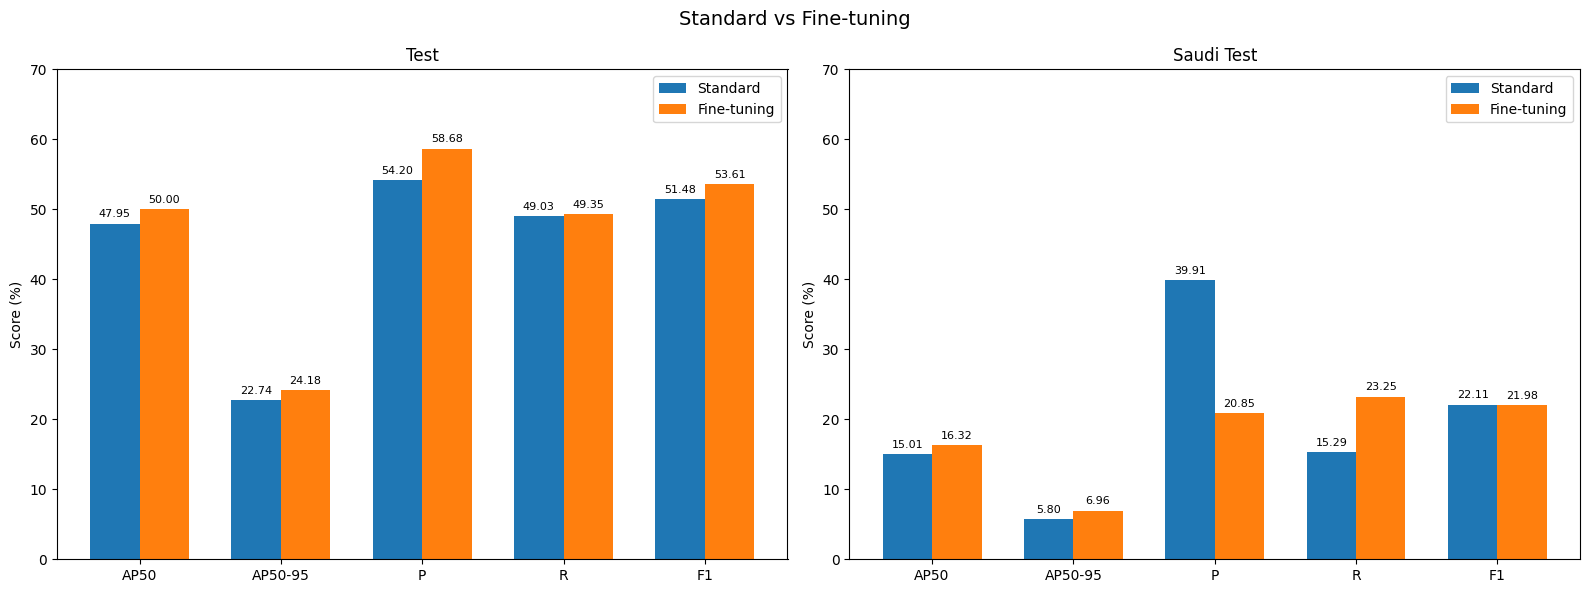

In [19]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ["AP50", "AP50-95", "P", "R", "F1"]

# Test results
standard_test = [47.95, 22.74, 54.20, 49.03, 51.48]
finetuning_test = [50.00, 24.18, 58.68, 49.35, 53.61]

# Saudi Test results
standard_saudi = [15.01, 5.80, 39.91, 15.29, 22.11]
finetuning_saudi = [16.32, 6.96, 20.85, 23.25, 21.98]

x = np.arange(len(metrics))
width = 0.35

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# =========================
# TEST
# =========================
bars1 = axes[0].bar(
    x - width/2,
    standard_test,
    width,
    label="Standard"
)

bars2 = axes[0].bar(
    x + width/2,
    finetuning_test,
    width,
    label="Fine-tuning"
)

axes[0].set_title("Test")
axes[0].set_ylabel("Score (%)")
axes[0].set_xticks(x)
axes[0].set_xticklabels(metrics)
axes[0].set_ylim(0, 70)
axes[0].legend()

axes[0].bar_label(bars1, fmt="%.2f", padding=3, fontsize=8)
axes[0].bar_label(bars2, fmt="%.2f", padding=3, fontsize=8)


# =========================
# SAUDI TEST
# =========================
bars3 = axes[1].bar(
    x - width/2,
    standard_saudi,
    width,
    label="Standard"
)

bars4 = axes[1].bar(
    x + width/2,
    finetuning_saudi,
    width,
    label="Fine-tuning"
)

axes[1].set_title("Saudi Test")
axes[1].set_ylabel("Score (%)")
axes[1].set_xticks(x)
axes[1].set_xticklabels(metrics)
axes[1].set_ylim(0, 70)
axes[1].legend()

axes[1].bar_label(bars3, fmt="%.2f", padding=3, fontsize=8)
axes[1].bar_label(bars4, fmt="%.2f", padding=3, fontsize=8)

plt.suptitle("Standard vs Fine-tuning", fontsize=14)

plt.tight_layout()
plt.show()